In [1]:
import sys

print(sys.version)
print(sys.executable)

3.11.16 (main, Aug 12 2026, 23:03:19) [Clang 21.0.0 (clang-2100.1.1.101)]
/Users/worlasiodeifianko/Desktop/Portifolio/.venv/bin/python


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sqlalchemy import create_engine, text

# Connect to our PostgreSQL database
engine = create_engine(
    "postgresql+psycopg2:///pharma_intelligence"
)

# Extract analytical datasets
with engine.connect() as connection:

    events = pd.read_sql_query(
        text("SELECT * FROM verification_events"),
        connection
    )

    products = pd.read_sql_query(
        text("SELECT * FROM products"),
        connection
    )

    batches = pd.read_sql_query(
        text("SELECT * FROM batches"),
        connection
    )

    locations = pd.read_sql_query(
        text("SELECT * FROM locations"),
        connection
    )

# Convert timestamps
events["event_timestamp"] = pd.to_datetime(
    events["event_timestamp"], utc=True
)

print("Database extraction successful!")

print("Events:", events.shape)
print("Products:", products.shape)
print("Batches:", batches.shape)
print("Locations:", locations.shape)

Database extraction successful!
Events: (50000, 8)
Products: (50, 4)
Batches: (200, 5)
Locations: (101, 4)


In [3]:
events.head()

,event_id,serial_number,product_id,batch_id,location_id,event_timestamp,verification_status,response_reason
0,E0000001,SN0000001,P016,B147,L056,2026-08-23 06:37:59.960146+00:00,SUCCESS,SUCCESS
1,E0000002,SN0000002,P018,B008,L095,2026-02-04 07:44:59.960146+00:00,SUCCESS,SUCCESS
2,E0000003,SN0000003,P040,B053,L046,2026-07-01 20:38:59.960146+00:00,SUCCESS,SUCCESS
3,E0000004,SN0000004,P023,B059,L061,2026-11-17 01:30:59.960146+00:00,SUCCESS,SUCCESS
4,E0000005,SN0000005,P042,B051,L014,2025-12-29 04:50:59.960146+00:00,UNKNOWN_PRODUCT,UNKNOWN_PRODUCT


In [4]:
events.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 8 columns):
 #   Column               Non-Null Count  Dtype              
---  ------               --------------  -----              
 0   event_id             50000 non-null  object             
 1   serial_number        50000 non-null  object             
 2   product_id           50000 non-null  object             
 3   batch_id             50000 non-null  object             
 4   location_id          50000 non-null  object             
 5   event_timestamp      50000 non-null  datetime64[ns, UTC]
 6   verification_status  50000 non-null  object             
 7   response_reason      50000 non-null  object             
dtypes: datetime64[ns, UTC](1), object(7)
memory usage: 3.1+ MB


In [5]:
events.describe(include="all")

,event_id,serial_number,product_id,batch_id,location_id,event_timestamp,verification_status,response_reason
count,50000,50000,50000,50000,50000,50000,50000,50000
unique,50000,49990,50,200,101,NaN,5,5
top,E0000001,SN0000100,P015,B021,L006,NaN,SUCCESS,SUCCESS
freq,1,11,1073,1042,557,NaN,44006,44006
mean,NaN,NaN,NaN,NaN,NaN,2026-05-25 21:34:18.203746048+00:00,NaN,NaN
min,NaN,NaN,NaN,NaN,NaN,2025-11-24 10:49:59.960146+00:00,NaN,NaN
25%,NaN,NaN,NaN,NaN,NaN,2026-02-23 19:02:14.960145920+00:00,NaN,NaN
50%,NaN,NaN,NaN,NaN,NaN,2026-05-25 23:45:29.960145920+00:00,NaN,NaN
75%,NaN,NaN,NaN,NaN,NaN,2026-08-25 07:44:14.960145920+00:00,NaN,NaN
max,NaN,NaN,NaN,NaN,NaN,2026-11-24 10:24:59.960146+00:00,NaN,NaN


In [6]:
status_counts = events["verification_status"].value_counts()

status_percentages = (
    events["verification_status"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

outcomes = pd.DataFrame({
    "Total Events": status_counts,
    "Percentage": status_percentages
})

display(outcomes)

,Total Events,Percentage
verification_status,,
SUCCESS,44006,88.01
EXPIRED,1998,4.00
UNKNOWN_PRODUCT,1748,3.50
ALREADY_DECOMMISSIONED,1240,2.48
RECALLED,1008,2.02


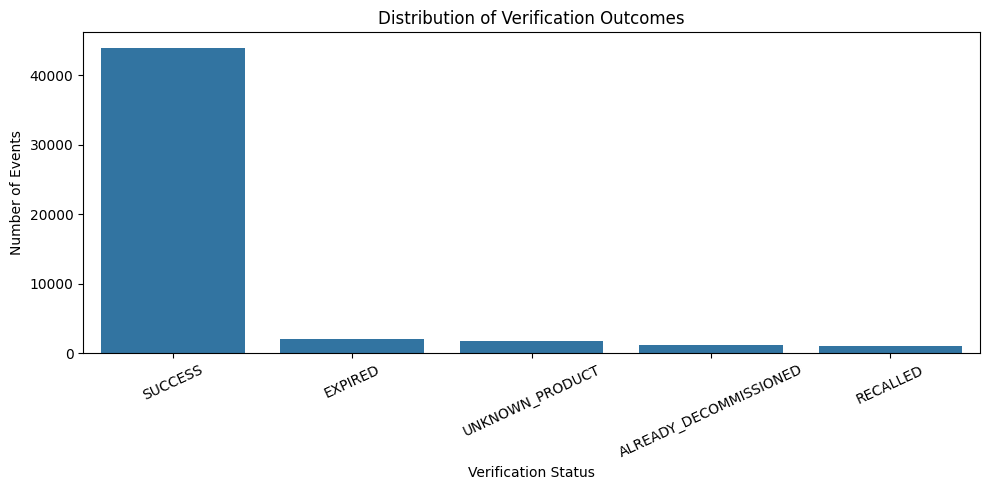

In [7]:
plt.figure(figsize=(10, 5))

sns.barplot(
    x=status_counts.index,
    y=status_counts.values
)

plt.title("Distribution of Verification Outcomes")
plt.xlabel("Verification Status")
plt.ylabel("Number of Events")
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

In [8]:
country_analysis = (
    events
    .merge(
        locations[["location_id", "country"]],
        on="location_id",
        how="left"
    )
    .groupby("country")
    .size()
    .reset_index(name="total_events")
    .sort_values("total_events", ascending=False)
)

display(country_analysis)

,country,total_events
1,France,8034
0,Belgium,7987
3,Italy,7483
7,Spain,6561
6,Portugal,6011
2,Germany,5392
4,Netherlands,4990
5,Poland,3537
8,Unknown,5


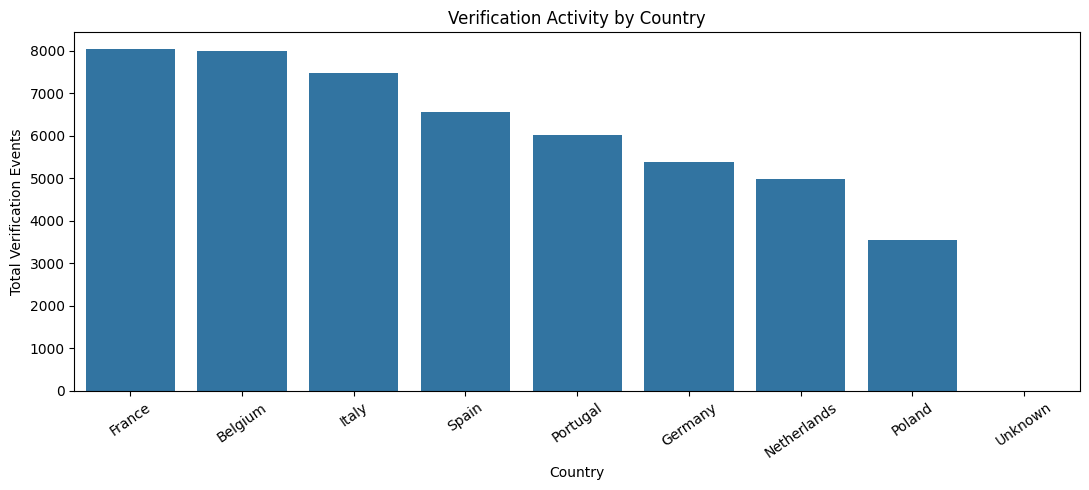

In [9]:
plt.figure(figsize=(11, 5))

sns.barplot(
    data=country_analysis,
    x="country",
    y="total_events"
)

plt.title("Verification Activity by Country")
plt.xlabel("Country")
plt.ylabel("Total Verification Events")
plt.xticks(rotation=35)
plt.tight_layout()
plt.show()

In [10]:
serial_analysis = (
    events
    .groupby("serial_number")
    .size()
    .reset_index(name="scan_count")
)

repeated_serials = serial_analysis[
    serial_analysis["scan_count"] > 1
].sort_values("scan_count", ascending=False)

display(repeated_serials.head(20))

,serial_number,scan_count
99,SN0000100,11


In [11]:
print(
    "Repeated serial numbers:",
    len(repeated_serials)
)

print(
    "Events associated with repeated serials:",
    repeated_serials["scan_count"].sum()
)

Repeated serial numbers: 1
Events associated with repeated serials: 11


In [12]:
expiry_analysis = events.merge(
    batches[["batch_id", "expiry_date"]],
    on="batch_id",
    how="left"
)

expiry_analysis["expiry_date"] = pd.to_datetime(
    expiry_analysis["expiry_date"]
)

expiry_analysis["expired_at_scan"] = (
    expiry_analysis["event_timestamp"].dt.tz_localize(None)
    .dt.normalize()
    >
    expiry_analysis["expiry_date"]
)

print(
    "Events occurring after batch expiry:",
    expiry_analysis["expired_at_scan"].sum()
)

Events occurring after batch expiry: 3122


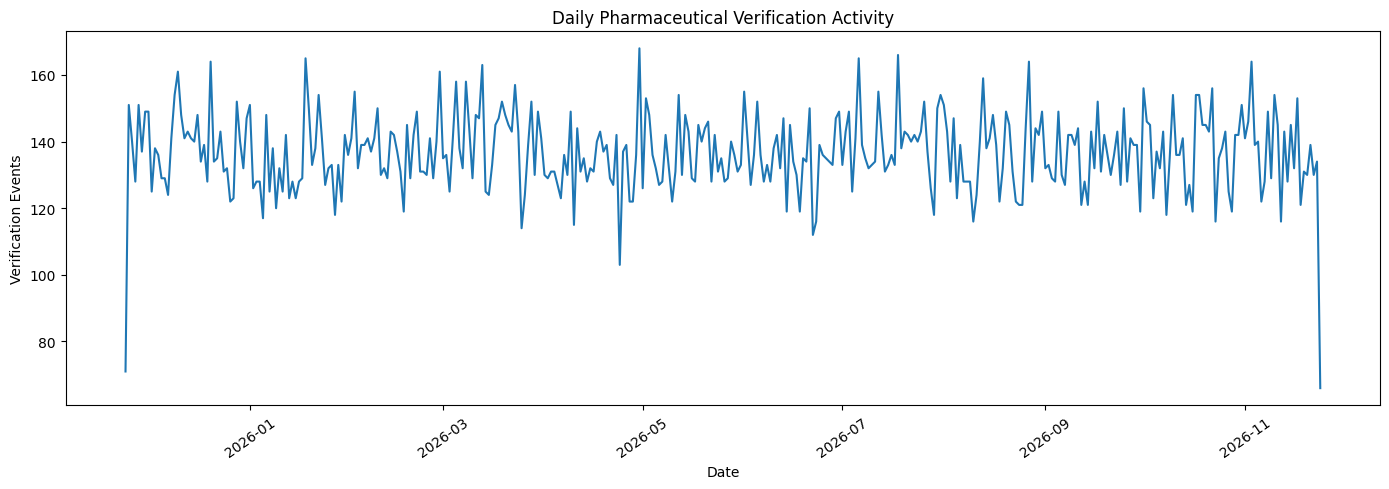

In [13]:
events["event_date"] = (
    events["event_timestamp"].dt.date
)

daily_activity = (
    events
    .groupby("event_date")
    .size()
    .reset_index(name="total_events")
)

plt.figure(figsize=(14, 5))

sns.lineplot(
    data=daily_activity,
    x="event_date",
    y="total_events"
)

plt.title("Daily Pharmaceutical Verification Activity")
plt.xlabel("Date")
plt.ylabel("Verification Events")
plt.xticks(rotation=35)
plt.tight_layout()
plt.show()

In [14]:
expiry_analysis = events.merge(
    batches[["batch_id", "expiry_date"]],
    on="batch_id",
    how="left"
)

expiry_analysis["expiry_date"] = pd.to_datetime(
    expiry_analysis["expiry_date"]
).dt.date

expiry_analysis["event_date"] = (
    expiry_analysis["event_timestamp"].dt.date
)

expiry_analysis["expired_at_scan"] = (
    expiry_analysis["event_date"]
    > expiry_analysis["expiry_date"]
)

print(
    "Events after batch expiry:",
    expiry_analysis["expired_at_scan"].sum()
)

Events after batch expiry: 3122


In [18]:
import os

In [19]:
os.makedirs("data/processed", exist_ok=True)

country_analysis.to_csv(
    "data/processed/country_analysis.csv",
    index=False
)

repeated_serials.to_csv(
    "data/processed/repeated_serials.csv",
    index=False
)

daily_activity.to_csv(
    "data/processed/daily_activity.csv",
    index=False
)

print("EDA outputs exported successfully.")

EDA outputs exported successfully.
